# Problem Framing
I predict squared-log-return of bitcoin, and horizon of forecasting is 7 days.

It is used to estimate the volatility when adding Bitcoin to a portfolio, and to facilitate appropriate risk management.


# Model Comparison
I predict squared-log-return of bitcoin, and horizon of forecasting is 7 days.

It is used to estimate the volatility when adding Bitcoin to a portfolio, and to facilitate appropriate risk management.

In [2]:
## Data Load

import sys
from pathlib import Path

support_dir = Path.cwd().parent.joinpath("capstone_support")

sys.path.append(str(support_dir))

from capstone_data import load_dataset, chronological_split

df = load_dataset("bitcoin")

train, validation, test = chronological_split(df)

print(df.attrs["capstone"]["preparation"])
print(train.shape, validation.shape, test.shape)

Daily adjusted OHLC; explicit auto_adjust=True; natural-log close-to-close return and its square. First return is missing. No rolling target or future-return features precomputed. Bitcoin horizons count calendar days.
(1096, 7) (365, 7) (366, 7)


In [24]:
train = train[1:]

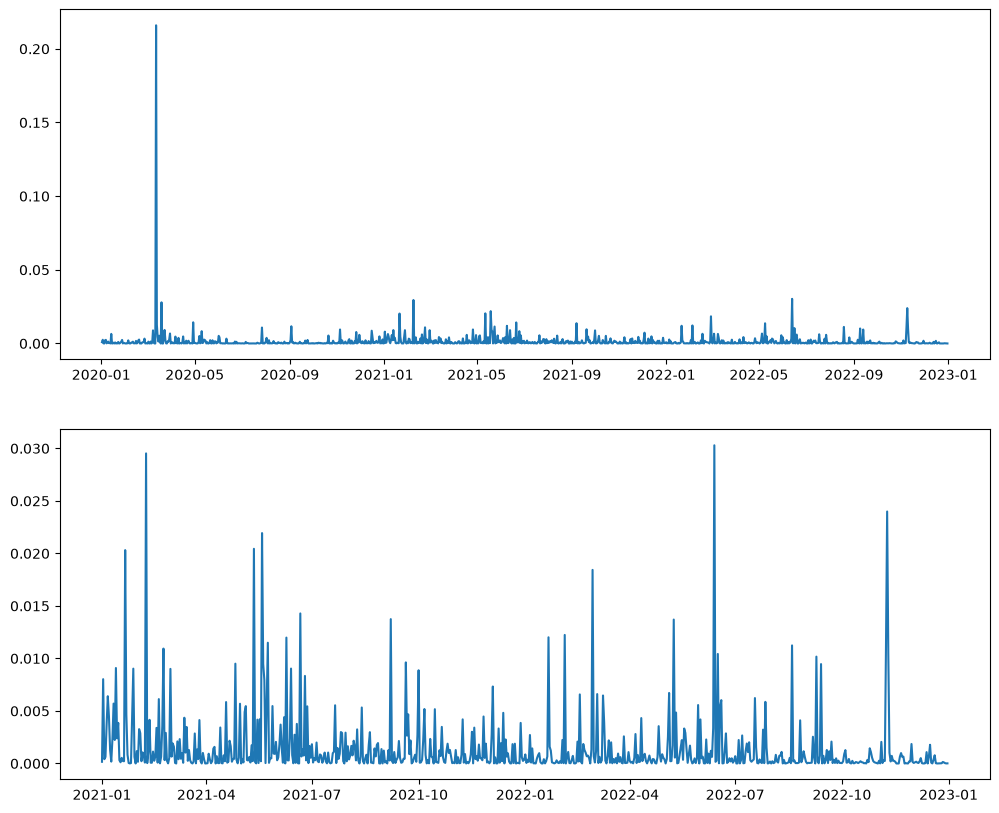

In [14]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(2, 1, figsize = (12, 10))

ax[0].plot(train["squared_log_return"])

ax[1].plot(train["squared_log_return"]["2021-01-01":"2022-12-31"])

Looking at the two graphs, it appears that the squared log returns of Bitcoin form clusters with some periods exhibiting high variance and others showing lower variance.

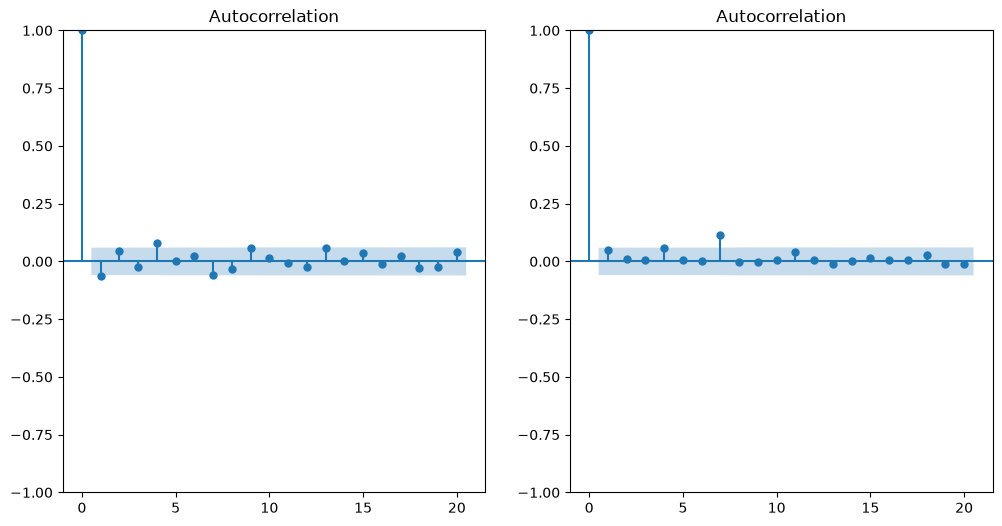

LM-test 1th p-value: 0.10722991276246539
LM-test 2th p-value: 0.264638725960999
LM-test 3th p-value: 0.44528729207181506
LM-test 4th p-value: 0.17720134702829843
LM-test 5th p-value: 0.27785017074180696
LM-test 6th p-value: 0.39112567596535064
LM-test 7th p-value: 0.005484032514378086
LM-test 8th p-value: 0.0089994770004167
LM-test 9th p-value: 0.015760086577003094
LM-test 10th p-value: 0.025424566177555306


c:\Users\taku\Documents\Graduation_Course\MATH546_Intro_timeseries_and_forecasting\Capstone\MATH546_Capstone\venv_capstone\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [53]:
import statsmodels.api as sm
import numpy as np
from statsmodels.graphics.tsaplots import plot_acf
import pandas as pd
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox

demeaned = train["log_return"] - train["log_return"].mean()

fig, axes = plt.subplots(1,2 , figsize = (12, 6))

plot_acf(demeaned, lags = 20, ax = axes[0])
plot_acf(demeaned**2, lags = 20, ax = axes[1])

plt.show()


test_lags = range(1,11)
for test in test_lags:
    lm_stat, lm_pvalue, f_stat, f_pvalue = het_arch(demeaned, nlags = test)

    print(f"LM-test {test}th p-value: {lm_pvalue}")

There is significant autocorrelation at lag 7.

In [58]:
lags_to_test = [5,7,10,20]
lb = acorr_ljungbox(demeaned, lags=lags_to_test, return_df=True)
lb_2 = acorr_ljungbox(demeaned**2, lags=lags_to_test, return_df=True)
print(lb.to_string())
print(lb_2.to_string())

      lb_stat  lb_pvalue
5   14.344533   0.013563
7   18.914276   0.008460
10  24.008843   0.007577
20  34.032216   0.025908
      lb_stat  lb_pvalue
5    6.512047   0.259531
7   20.502075   0.004581
10  20.593777   0.024111
20  23.937604   0.245128


In addition, L-jung box test suggests that there is a autocorrelation in both log_return and squared_log_return.

In [50]:
from arch import arch_model

model_arch = arch_model(train["log_return"], vol = "Arch", p = 7, rescale=False)
model_garch = arch_model(train["log_return"], vol = "Garch", p = 1, q = 1, rescale=False)
model_tgarch = arch_model(train["log_return"], vol = "Garch", p = 1, q = 1, dist = "studentst", rescale=False)

arch_result = model_arch.fit(disp = "off")
garch_result = model_garch.fit(disp = "off")
tgarch_result = model_tgarch.fit(disp = "off")

print(arch_result.summary())

                      Constant Mean - ARCH Model Results                      
Dep. Variable:             log_return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                       ARCH   Log-Likelihood:                2069.08
Distribution:                  Normal   AIC:                          -4120.16
Method:            Maximum Likelihood   BIC:                          -4075.19
                                        No. Observations:                 1093
Date:                Thu, Nov 05 2026   Df Residuals:                     1092
Time:                        02:08:30   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu         1.5976e-03  1.149e-03      1.390      0.164 

In [45]:
print(garch_result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:             log_return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:                2026.32
Distribution:                  Normal   AIC:                          -4044.63
Method:            Maximum Likelihood   BIC:                          -4024.65
                                        No. Observations:                 1093
Date:                Thu, Nov 05 2026   Df Residuals:                     1092
Time:                        02:05:27   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu         1.5909e-03  1.106e-03      1.439      0.150 

In [46]:
print(tgarch_result.summary())

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                   log_return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:                1589.00
Distribution:      Standardized Student's t   AIC:                          -3168.00
Method:                  Maximum Likelihood   BIC:                          -3143.02
                                              No. Observations:                 1093
Date:                      Thu, Nov 05 2026   Df Residuals:                     1092
Time:                              02:05:27   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
m

I choose GARCH(1,1) based on BIC

(BIC of GARCH(1,1) is -4024.65 while BIC of t-GARCH(1,1) is -3143.02)

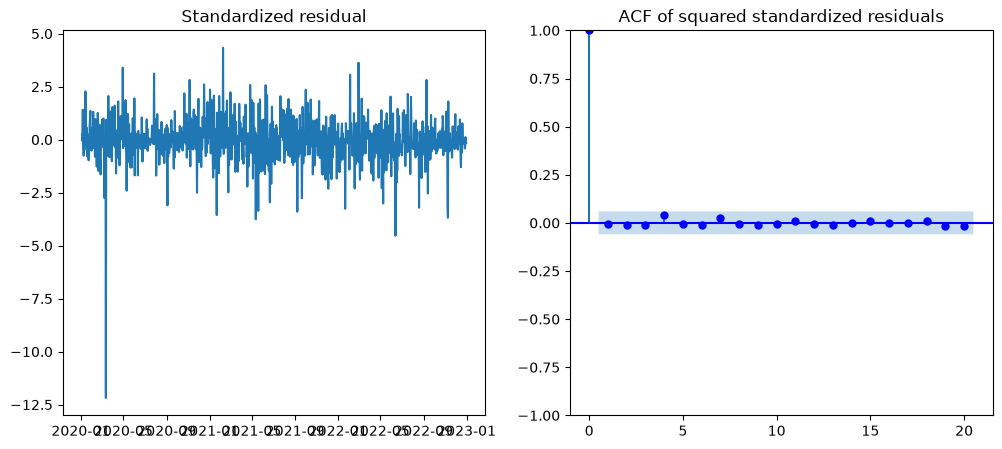

In [59]:
resid = garch_result.std_resid

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(resid)
axes[0].set_title("Standardized residual")
plot_acf(resid**2, ax = axes[1], lags = 20, color = "blue")
axes[1].set_title("ACF of squared standardized residuals")

plt.show()

The residual of GARCH(1,1) looks like stationary in left graph, and there is no autocorrelation in right graph